# Plasma end vs. waveform end

Delta = waveform end time − plasma end time, per shot and stabilisation type [µs].
The plasma end is read from a JSON field you enter in `PLASMA_END_FIELD`. Requires numpy and matplotlib, and network access to the archive.

In [1]:
from pathlib import Path
import sys

repo = Path().cwd().parent
sys.path.insert(0, str(repo / "src"))

from golemLLM.core.client import GolemCLIENThttp, Caching
from golemLLM.parsing import getShotJSONfield, last_sample

client = GolemCLIENThttp("http://golem.fjfi.cvut.cz/shots", cache=Caching.FILESYSTEM)

In [2]:
PLASMA_END_FILE = "Diagnostics/PlasmaDetection/Results/t_plasma_duration"

In [3]:
WAVEFORM_FIELDS = {
    "radial": "parameters/infrastructure.position_stabilization/radial_waveform",
    "vertical": "parameters/infrastructure.position_stabilization/vertical_waveform",
    "current": "parameters/infrastructure.current_stabilization/waveform",
}

deltas = {}  # (shot, waveform name) -> (plasma end [µs], waveform end [µs], delta [µs])

for shot in range(54650, 54785+1, 1):
    try:
        plasma_num = float(client.getShotFileCached(shot, PLASMA_END_FILE))
        if plasma_num < 0:
            raise ValueError(f"Shot {shot} plasma end: negative value {plasma_num}, no plasma?")
        plasma_end = plasma_num * 1000;
    except Exception as e:
        print(f"Shot {shot} plasma end: {e}")
        continue
    for name, field in WAVEFORM_FIELDS.items():
        try:
            waveform_end, _ = last_sample(getShotJSONfield(client, shot, "conductor/discharge.json", field), offset=1)
        except Exception as e:
            print(f"Shot {shot} {name}: {e}")
            continue
        deltas[(shot, name)] = (plasma_end, waveform_end, waveform_end - plasma_end)

for (shot, name), (plasma_end, waveform_end, delta) in deltas.items():
    print(f"Shot {shot} {name:8s} plasma end {plasma_end:>10g} µs  waveform second-to-last {waveform_end:>10g} µs  delta {delta:+g} µs")

Shot 54650 radial: 'infrastructure.position_stabilization'
Shot 54650 vertical: 'infrastructure.position_stabilization'
Shot 54650 current: 'infrastructure.current_stabilization'
Shot 54651 radial: 'infrastructure.position_stabilization'
Shot 54651 vertical: 'infrastructure.position_stabilization'
Shot 54651 current: 'infrastructure.current_stabilization'
Shot 54652 radial: 'infrastructure.position_stabilization'
Shot 54652 vertical: 'infrastructure.position_stabilization'
Shot 54652 current: 'infrastructure.current_stabilization'
Shot 54653 radial: 'infrastructure.position_stabilization'
Shot 54653 vertical: 'infrastructure.position_stabilization'
Shot 54653 current: 'infrastructure.current_stabilization'
Shot 54654 radial: 'infrastructure.position_stabilization'
Shot 54654 vertical: 'infrastructure.position_stabilization'
Shot 54654 current: 'infrastructure.current_stabilization'
Shot 54655 radial: 'infrastructure.position_stabilization'
Shot 54655 vertical: 'infrastructure.position_

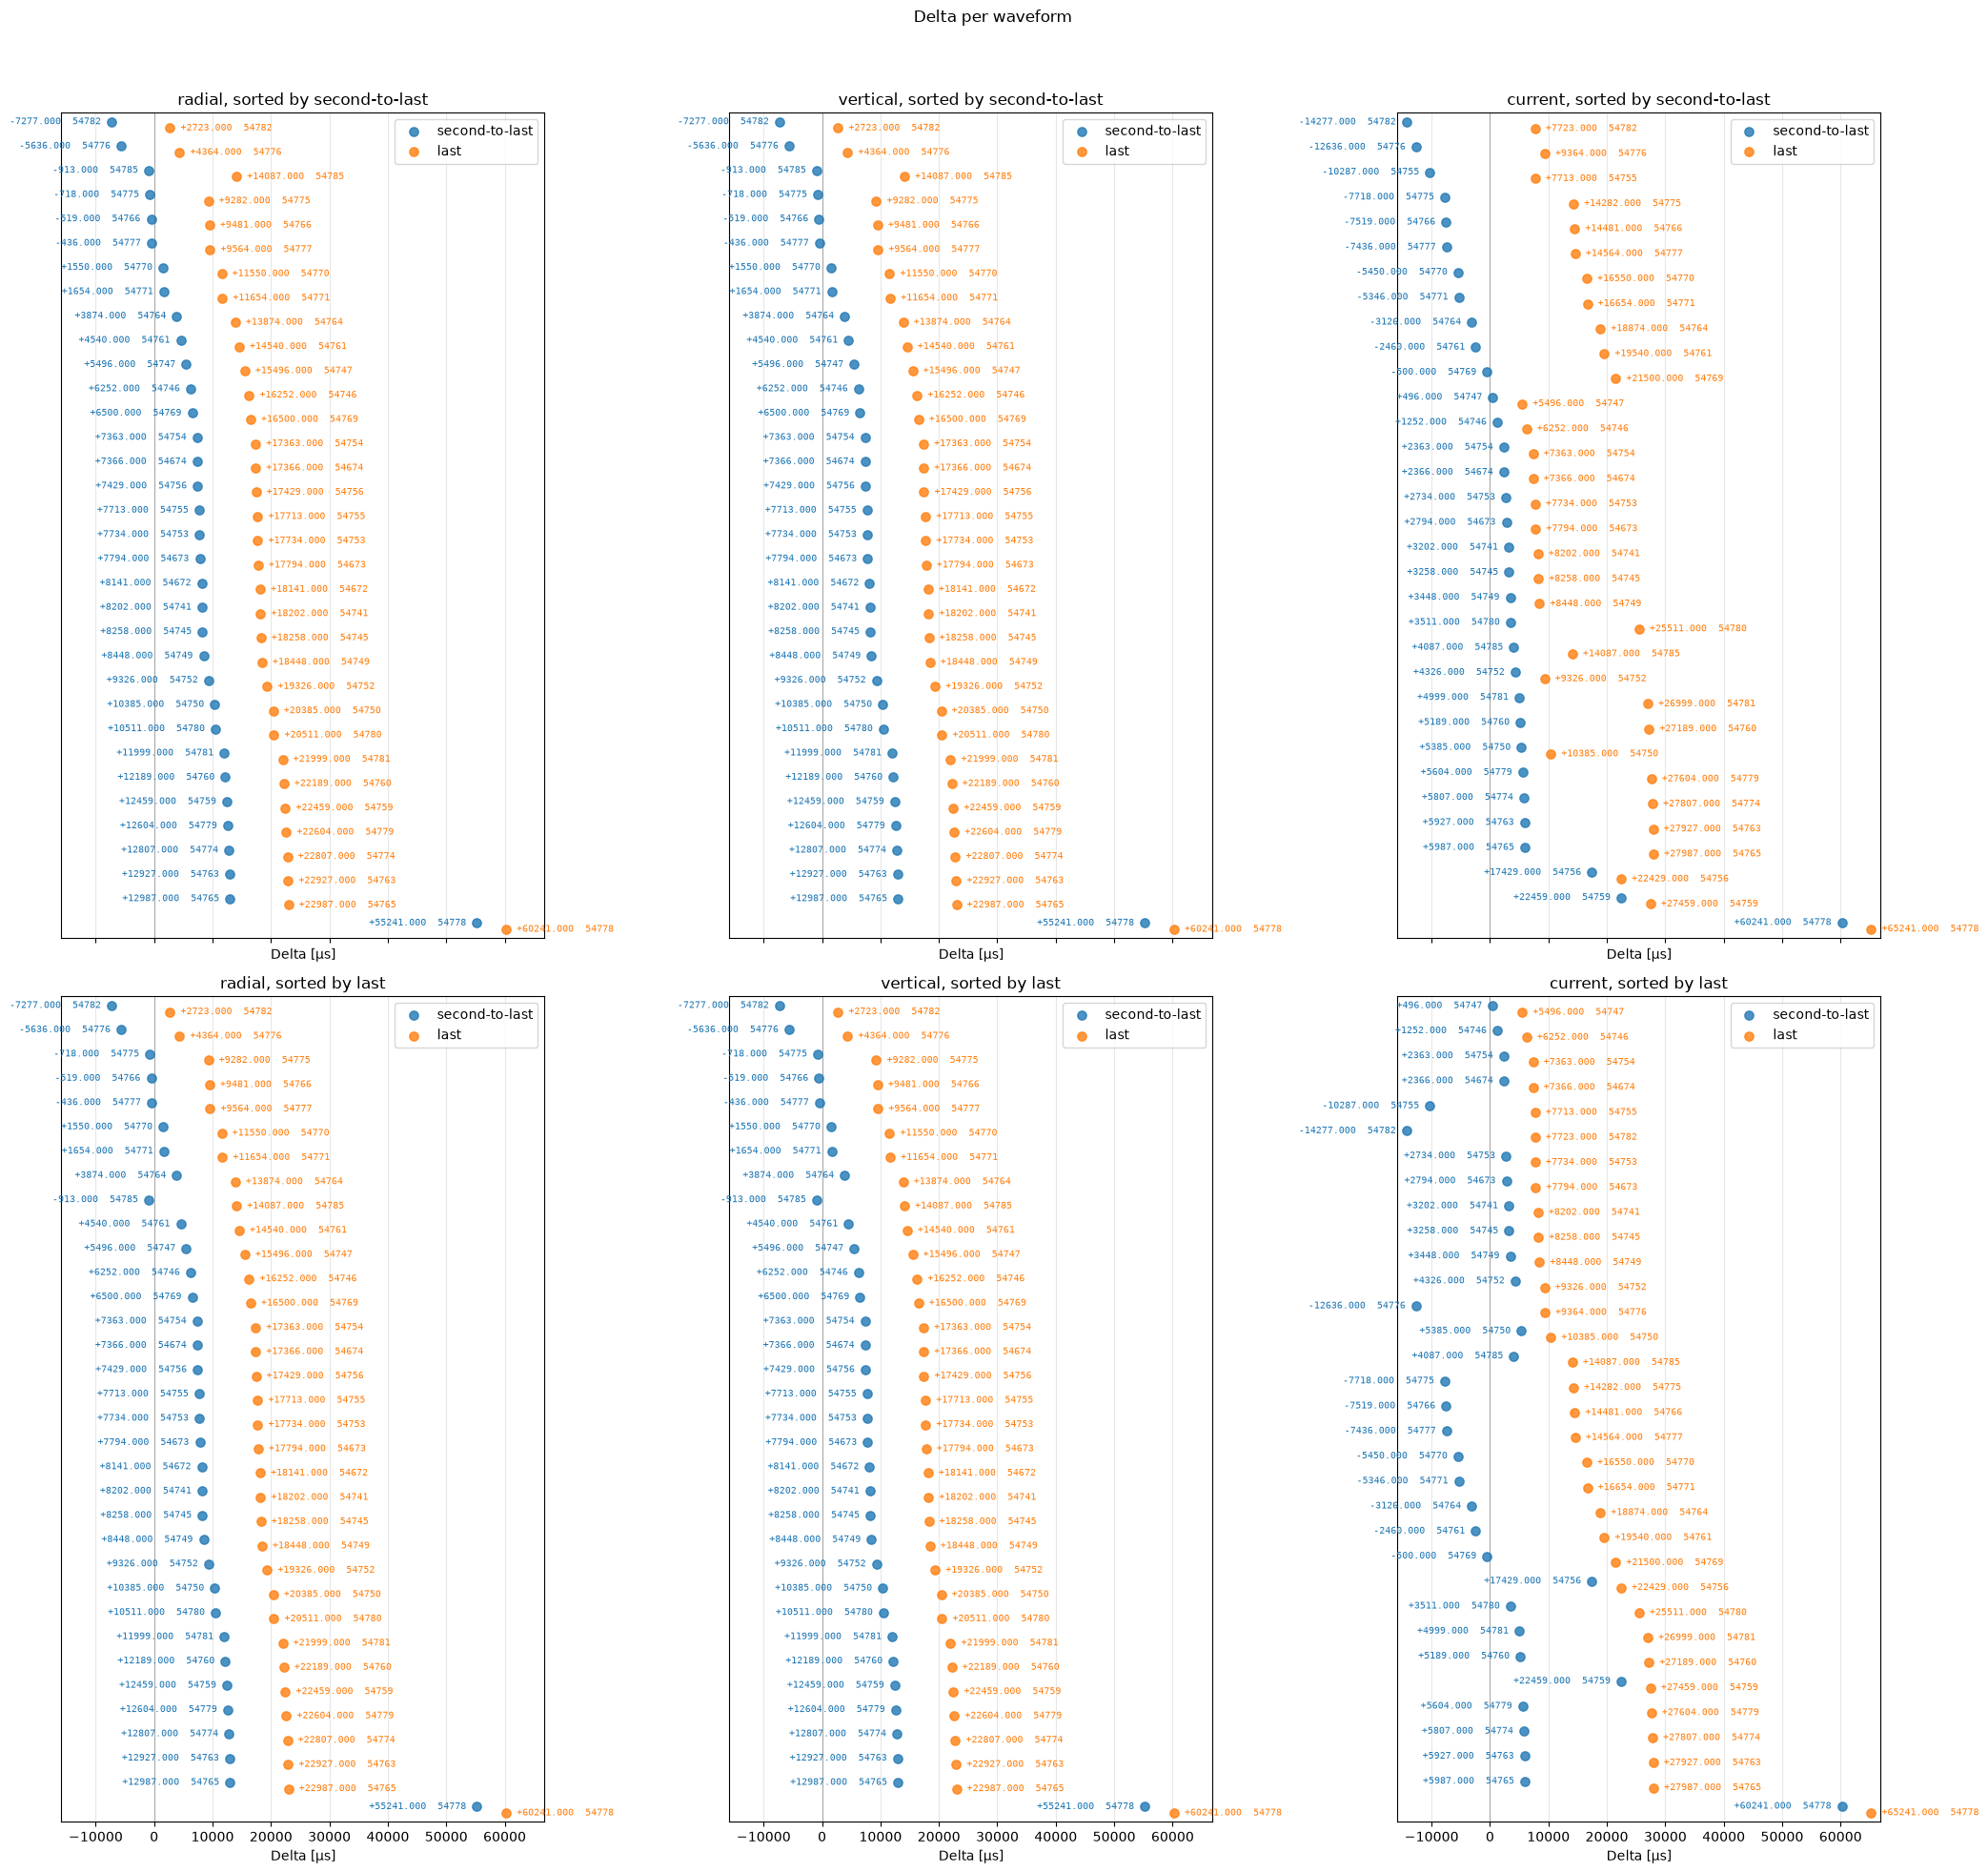

In [10]:
names = list(WAVEFORM_FIELDS)
panels = {
    name: defaultdict(lambda: {"second-to-last": [], "last": []})
    for name in names
}

for source, kind in (
    (deltas, "second-to-last"),
    (last_deltas, "last"),
):
    for (shot, name), (_, _, delta) in source.items():
        panels[name][shot][kind].append(delta)

all_deltas = [
    delta
    for panel in panels.values()
    for groups in panel.values()
    for values in groups.values()
    for delta in values
]

x_min, x_max = (
    (min(all_deltas), max(all_deltas))
    if all_deltas
    else (-1, 1)
)
x_padding = max((x_max - x_min) * 0.02, 1)

fig, axes = plt.subplots(
    2,
    len(names),
    figsize=(7 * len(names), 20),
    sharex=True,
    squeeze=False,
)

sort_kinds = ("second-to-last", "last")

for row_index, sort_kind in enumerate(sort_kinds):
    for ax, name in zip(axes[row_index], names):
        sorted_rows = sorted(
            panels[name].items(),
            key=lambda item: min(
                item[1][sort_kind],
                default=float("inf"),
            ),
        )

        ax.set_title(f"{name}, sorted by {sort_kind}")
        legend_labels = set()

        for y, (shot, groups) in enumerate(sorted_rows):
            present = [
                kind for kind in sort_kinds if groups[kind]
            ]

            if len(present) == 2:
                positions = [
                    ("second-to-last", y - 0.13, "C0", -8, "right"),
                    ("last", y + 0.13, "C1", 8, "left"),
                ]
            else:
                kind = present[0]
                positions = [
                    (
                        kind,
                        y,
                        "C0" if kind == "second-to-last" else "C1",
                        -8 if kind == "second-to-last" else 8,
                        "right" if kind == "second-to-last" else "left",
                    )
                ]

            for kind, y_pos, color, x_offset, alignment in positions:
                for delta in groups[kind]:
                    label = (
                        kind
                        if kind not in legend_labels
                        else None
                    )
                    legend_labels.add(kind)

                    ax.scatter(
                        delta,
                        y_pos,
                        s=45,
                        color=color,
                        alpha=0.8,
                        zorder=3,
                        label=label,
                    )

                    ax.annotate(
                        f"{delta:+.3f}  {shot}",
                        (delta, y_pos),
                        textcoords="offset points",
                        xytext=(x_offset, 0),
                        ha=alignment,
                        va="center",
                        fontsize=7,
                        family="monospace",
                        color=color,
                    )

        ax.axvline(0, color="grey", lw=0.8, alpha=0.6)
        ax.set_ylim(len(sorted_rows) - 0.5, -0.5)
        ax.set_yticks([])
        ax.set_xlim(x_min - x_padding, x_max + x_padding)
        ax.set_xlabel("Delta [µs]")
        ax.grid(axis="x", alpha=0.3)
        ax.legend()

fig.suptitle("Delta per waveform")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()
